In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [ ]:
words = open("names.txt", "r").read().splitlines()
def stoi(c):
    if c == '.': return 26
    return ord(c)-ord('a')
def itos(i):
    if i == 26: return '.'
    return chr(ord('a')+i)

In [3]:
chunk_size = 3
emb_dim = 10
batch_size = 32
n_in = chunk_size*emb_dim
n_outs = [200, 27]

In [ ]:
xs = []
ys = []
for word in words:
    context = [26]*chunk_size
    word = word + '.'
    for i in range(len(word)):
        
        xs.append(context)
        ys.append(stoi(word[i]))
        context = context[1:] + [stoi(word[i])]
xs = torch.tensor(xs)
ys = torch.tensor(ys)
xs.shape, ys.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [5]:
n1 = int(xs.shape[0]*0.8)
n2 = int(xs.shape[0]*0.9)
xdev = xs[n1:n2]
ydev = ys[n1:n2]
xtest = xs[n2:]
ytest = ys[n2:]
xs = xs[:n1]
ys = ys[:n1]

In [ ]:
C = torch.randn((27,emb_dim))
W1 = torch.randn((n_in, n_outs[0]))
B1 = torch.randn(n_outs[0])
W2 = torch.rand((n_outs[0], n_outs[1]))
B2 = torch.rand(n_outs[1])
parameters = [C,W1,B1,W2,B2]
for param in parameters:
    param.requires_grad=True

In [7]:
# steps = 1000
# lre = torch.linspace(-3, 0, steps)
# losses = []
# for i in range(steps):
#     batch = torch.randint(0, xs.shape[0], (batch_size, ))
#     x = xs[batch]
#     y = ys[batch]
#     emb = C[x].view(-1, n_in) 
#     h = torch.tanh(emb @ W1 + B1)
#     logits = h @ W2 + B2
#     loss = F.cross_entropy(logits, y)
#     for param in parameters: param.grad = None
#     loss.backward()
#     for param in parameters: param.data -= 10**lre[i]*param.grad
#     losses.append(loss.item())
# plt.plot(lre, losses)


step: 0, loss 3.2966179847717285
step: 1000, loss 2.3647327423095703
step: 2000, loss 2.3975906372070312
step: 3000, loss 2.039923667907715
step: 4000, loss 2.3039627075195312
step: 5000, loss 2.1804420948028564
step: 6000, loss 2.168843984603882
step: 7000, loss 2.410398006439209
step: 8000, loss 2.636904001235962
step: 9000, loss 2.313978672027588
step: 10000, loss 2.1637797355651855
step: 11000, loss 1.9858927726745605
step: 12000, loss 1.9120633602142334
step: 13000, loss 1.923280119895935
step: 14000, loss 2.2825663089752197
step: 15000, loss 2.05117130279541
step: 16000, loss 2.281848192214966
step: 17000, loss 1.8883438110351562
step: 18000, loss 2.0959324836730957
step: 19000, loss 2.2933597564697266
step: 20000, loss 2.060755491256714
step: 21000, loss 2.2581465244293213
step: 22000, loss 1.8135744333267212
step: 23000, loss 1.7332940101623535
step: 24000, loss 2.308323621749878
step: 25000, loss 2.003565788269043
step: 26000, loss 2.3818857669830322
step: 27000, loss 2.101037

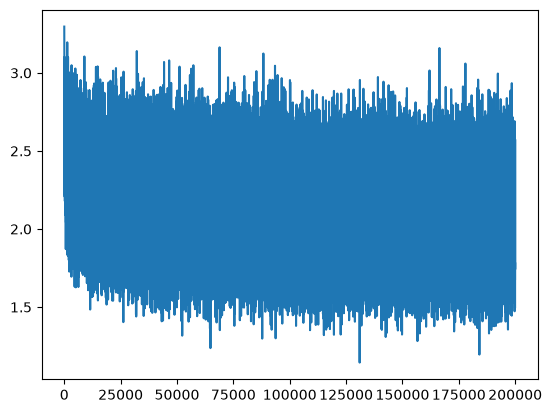

In [24]:
losses = []
for i in range(200000):
    batch = torch.randint(0, xs.shape[0], (batch_size, ))
    x = xs[batch]
    y = ys[batch]
    emb = C[x].view(-1, n_in) 
    h = torch.tanh(emb @ W1 + B1)
    logits = h @ W2 + B2
    loss = F.cross_entropy(logits, y)
    for param in parameters: param.grad = None
    loss.backward()
    for param in parameters: param.data -= (0.1 if i < 100000 else 0.01) * param.grad
    losses.append(loss.item())
    if i % 1000 == 0: print(f"step: {i}, loss {loss.item()}")
plt.plot(losses)


In [26]:
emb = C[xdev].view(-1, n_in) 
h = torch.tanh(emb @ W1 + B1)
logits = h @ W2 + B2
loss = F.cross_entropy(logits, ydev)
print(loss.data)
emb = C[xtest].view(-1, n_in) 
h = torch.tanh(emb @ W1 + B1)
logits = h @ W2 + B2
loss = F.cross_entropy(logits, ytest)
print(loss.data)



tensor(2.3647)
tensor(2.3821)


In [22]:
for i in range(10):
    name = ""
    context = [26]*chunk_size
    while True:
        emb = C[(context, )].view(-1, emb_dim*chunk_size)
        h = torch.tanh(emb @ W1 + B1)
        logits = h @ W2 + B2
        probs = F.softmax(logits, dim = 1)
        idx = torch.multinomial(probs, num_samples=1)
        name+=itos(idx)
        context = context[1:] + [idx]
        if idx == 26: break
    print(name)
    

sephristyn.
evonne.
boweanaxtin.
kasha.
dana.
kymond.
lenavey.
trin.
jailah.
milianovan.
